In [1]:
! pip install pandas scikit-learn seaborn matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

In [3]:
fake_news = pd.read_csv("../data/fake.csv")
true_news = pd.read_csv("../data/true.csv")

print("Fake news records:", len(fake_news))
print("Real news records:", len(true_news))

Fake news records: 23481
Real news records: 21417


In [4]:
fake_news["label"] = 0
true_news["label"] = 1

print("Fake news label:", fake_news["label"].iloc[0])
print("Real news label:", true_news["label"].iloc[0])

Fake news label: 0
Real news label: 1


In [5]:
data = pd.concat([fake_news, true_news], ignore_index=True)

data = data.sample(frac=1, random_state=42)

data.reset_index(drop=True, inplace=True)

print("Total records:", len(data))
data.head()

Total records: 44898


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [6]:
print("Dataset shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isnull().sum())

Dataset shape: (44898, 5)

Columns:
['title', 'text', 'subject', 'date', 'label']

Missing values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [7]:
data["title"] = data["title"].fillna("")
data["text"] = data["text"].fillna("")

print("Missing values handled successfully.")

Missing values handled successfully.


In [8]:
data["content"] = data["title"] + " " + data["text"]

print(data["content"].head())

0    Ben Stein Calls Out 9th Circuit Court: Committ...
1    Trump drops Steve Bannon from National Securit...
2    Puerto Rico expects U.S. to lift Jones Act shi...
3     OOPS: Trump Just Accidentally Confirmed He Le...
4    Donald Trump heads for Scotland to reopen a go...
Name: content, dtype: object


In [9]:
print("Records before removing duplicates:", len(data))

data.drop_duplicates(subset=["content"], inplace=True)

data.reset_index(drop=True, inplace=True)

print("Records after removing duplicates:", len(data))

Records before removing duplicates: 44898
Records after removing duplicates: 39105


In [10]:
data["content"] = data["content"].str.lower()

print("Text converted to lowercase.")

Text converted to lowercase.


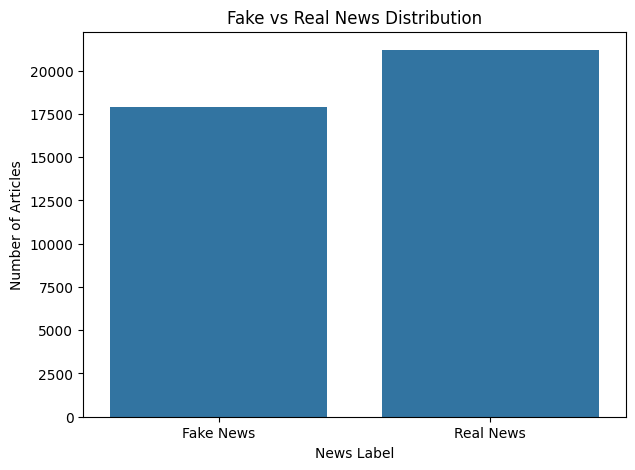

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(x="label", data=data)

plt.title("Fake vs Real News Distribution")
plt.xlabel("News Label")
plt.ylabel("Number of Articles")

plt.xticks(
    [0, 1],
    ["Fake News", "Real News"]
)

plt.show()

In [12]:
vectorizer = TfidfVectorizer(
    max_features=2000,
    stop_words="english"
)

X = vectorizer.fit_transform(data["content"])
y = data["label"]

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (39105, 2000)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.35,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 25418
Testing samples: 13687


In [14]:
nb_model = MultinomialNB()

lr_model = LogisticRegression(
    max_iter=500
)

svm_model = LinearSVC()

print("Models created successfully.")

Models created successfully.


In [15]:
print("Training Naive Bayes...")
nb_model.fit(X_train, y_train)

print("Training Logistic Regression...")
lr_model.fit(X_train, y_train)

print("Training Linear SVM...")
svm_model.fit(X_train, y_train)

print("\nAll models trained successfully.")

Training Naive Bayes...
Training Logistic Regression...
Training Linear SVM...

All models trained successfully.


In [16]:
nb_pred = nb_model.predict(X_test)

lr_pred = lr_model.predict(X_test)

svm_pred = svm_model.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


In [17]:
results = []

models = {
    "Naive Bayes": (nb_model, nb_pred),
    "Logistic Regression": (lr_model, lr_pred),
    "Linear SVM": (svm_model, svm_pred)
}

for name, (model, predictions) in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.928107,0.939129,0.927483,0.933270
1,Logistic Regression,0.985168,0.981195,0.991643,0.986391
2,Linear SVM,0.991817,0.990205,0.994743,0.992469


In [18]:
best_row = results_df.loc[
    results_df["F1-Score"].idxmax()
]

best_model_name = best_row["Model"]

print("Best Model:", best_model_name)
print("Accuracy:", best_row["Accuracy"])
print("Precision:", best_row["Precision"])
print("Recall:", best_row["Recall"])
print("F1-Score:", best_row["F1-Score"])

Best Model: Linear SVM
Accuracy: 0.9918170526777234
Precision: 0.9902052864618275
Recall: 0.9947432268499797
F1-Score: 0.9924690693921463


In [19]:
if best_model_name == "Naive Bayes":
    best_model = nb_model
    best_predictions = nb_pred

elif best_model_name == "Logistic Regression":
    best_model = lr_model
    best_predictions = lr_pred

else:
    best_model = svm_model
    best_predictions = svm_pred

print("Selected model:", best_model_name)

Selected model: Linear SVM


In [20]:
print("Classification Report")
print("=" * 60)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Fake News", "Real News"]
    )
)

Classification Report
              precision    recall  f1-score   support

   Fake News       0.99      0.99      0.99      6268
   Real News       0.99      0.99      0.99      7419

    accuracy                           0.99     13687
   macro avg       0.99      0.99      0.99     13687
weighted avg       0.99      0.99      0.99     13687



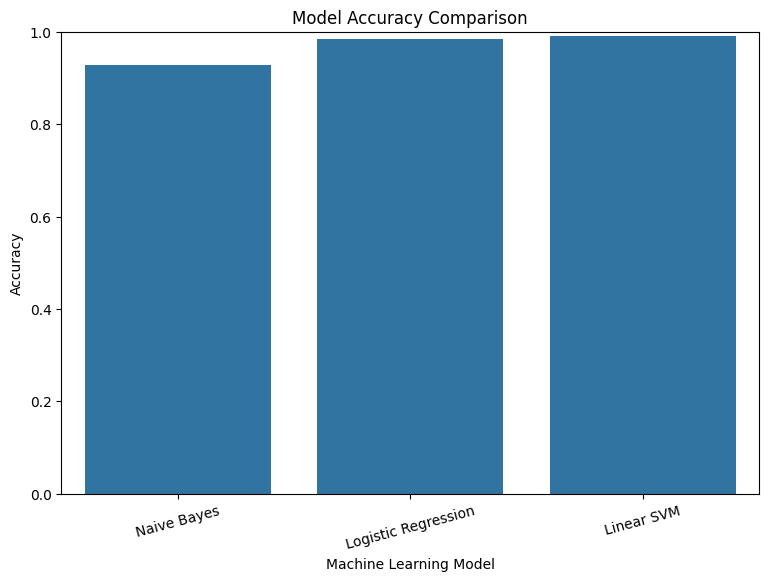

In [21]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

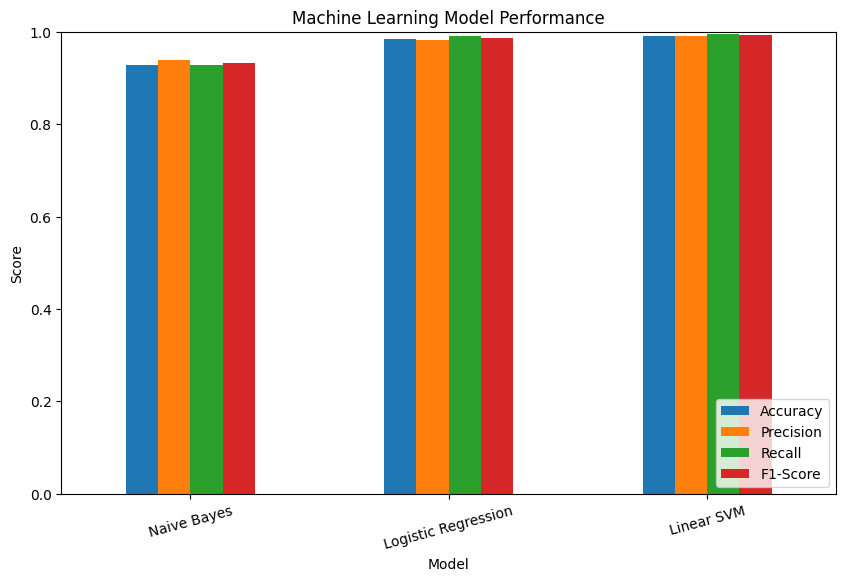

In [22]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Performance")
plt.xlabel("Model")
plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.legend(loc="lower right")

plt.show()

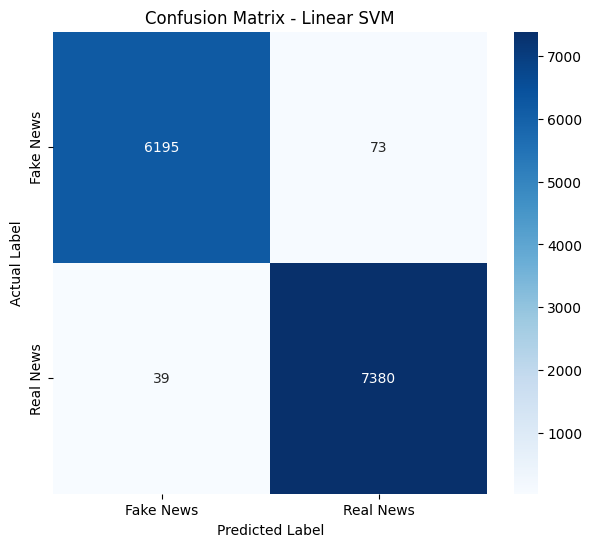

In [23]:
cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.title(f"Confusion Matrix - {best_model_name}")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [24]:
model_path = "../models/model.pkl"
vectorizer_path = "../models/vectorizer.pkl"

with open(model_path, "wb") as model_file:
    pickle.dump(best_model, model_file)

with open(vectorizer_path, "wb") as vectorizer_file:
    pickle.dump(vectorizer, vectorizer_file)

print("Best model saved successfully.")
print("Model:", best_model_name)
print("Model path:", model_path)
print("Vectorizer path:", vectorizer_path)

Best model saved successfully.
Model: Linear SVM
Model path: ../models/model.pkl
Vectorizer path: ../models/vectorizer.pkl


In [25]:
with open("../models/model.pkl", "rb") as model_file:
    loaded_model = pickle.load(model_file)

with open("../models/vectorizer.pkl", "rb") as vectorizer_file:
    loaded_vectorizer = pickle.load(vectorizer_file)

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [26]:
def predict_news(news_text):

    transformed_text = loaded_vectorizer.transform([news_text])

    prediction = loaded_model.predict(transformed_text)[0]

    if prediction == 0:
        return "FAKE NEWS"
    else:
        return "REAL NEWS"

In [27]:
sample_news = """
The government announced a new policy that will come into effect next month.
"""

result = predict_news(sample_news)

print("Prediction:", result)

Prediction: FAKE NEWS
